In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Configuramos el estilo de las gráficas para que se vean profesionales en clase
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. GENERACIÓN DE DATOS (Ejemplo: Atletas)
# X: Horas de entrenamiento semanal de un grupo de atletas
X = np.array([2.0, 3.5, 5.0, 6.5, 8.0, 9.5, 11.0, 12.5, 14.0, 15.5])

# Y: Rendimiento estimado / Velocidad máxima o marca (en unidades de desempeño)
# Simulamos una relación lineal real: y = 1.5 * X + 10, con un poco de ruido realista
np.random.seed(42)
# y = 1.5 * X + 10,
Y = 1.5 * X + 10.0 + np.random.normal(0, 1.2, size=X.shape)

print(f"Datos cargados con éxito: {len(X)} atletas analizados.")

Datos cargados con éxito: 10 atletas analizados.


In [5]:
# 2. INICIALIZACIÓN DE PARÁMETROS
w = 0.0  #PESO Weight
b = 0.0  #Bias

# Hiperparámetros
learning_rate = 0.005  # Tasa de aprendizaje ajustada para esta escala
epochs = 3000          # Iteraciones de entrenamiento
n = len(X)
error_threshold = 0.001  # Umbral de error para detener el entrenamiento si se alcanza

# Historial para graficar la evolución del costo si lo deseas mostrar
historial_costos = []

# 3. ENTRENAMIENTO
for epoch in range(epochs):
    # Predicción actual
    Y_pred = w * X + b

    # Cálculo del Costo (MSE)
    cost = (1 / (2 * n)) * np.sum((Y_pred - Y) ** 2)
    historial_costos.append(cost)

    # Derivadas parciales (Gradientes)
    dw = (2 / n) * np.sum((Y_pred - Y) * X)
    db = (2 / n) * np.sum(Y_pred - Y)

    # Actualización de pesos
    w = w - learning_rate * dw
    b = b - learning_rate * db

print("¡Entrenamiento completado!")
print(f"Ecuación final aprendida: Rendimiento = {w:.4f} * (Horas de Entrenamiento) + {b:.4f}")

¡Entrenamiento completado!
Ecuación final aprendida: Rendimiento = 1.4973 * (Horas de Entrenamiento) + 10.5549


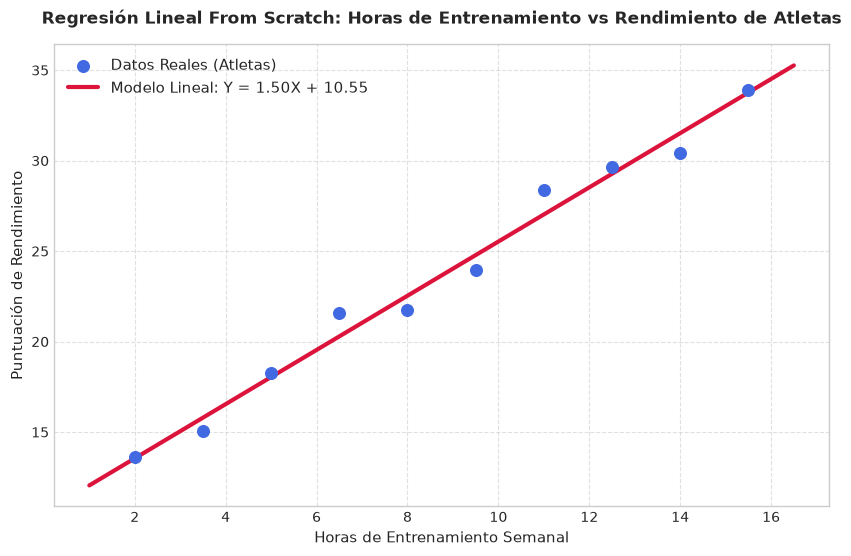

In [6]:
# 4. VISUALIZACIÓN DE RESULTADOS
plt.figure(figsize=(10, 6))

# Dibujar los puntos reales (Atletas)
plt.scatter(X, Y, color='royalblue', s=70, label='Datos Reales (Atletas)', zorder=5)

# Dibujar la línea de tendencia aprendida por el modelo
X_linea = np.linspace(min(X) - 1, max(X) + 1, 100)
Y_linea = w * X_linea + b
plt.plot(X_linea, Y_linea, color='crimson', linewidth=3, label=f'Modelo Lineal: Y = {w:.2f}X + {b:.2f}')

# Etiquetas y formato estético
plt.title('Regresión Lineal From Scratch: Horas de Entrenamiento vs Rendimiento de Atletas', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Horas de Entrenamiento Semanal', fontsize=11)
plt.ylabel('Puntuación de Rendimiento', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

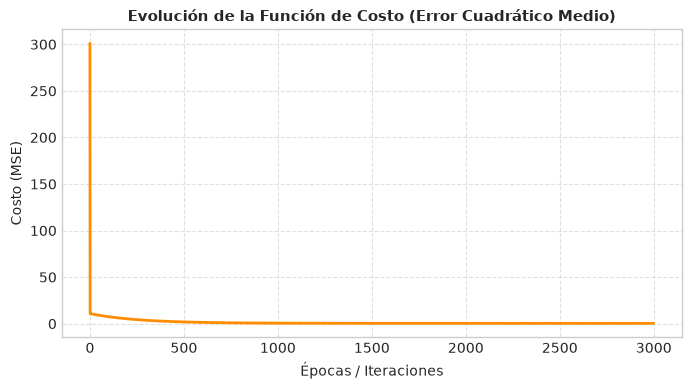

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(range(epochs), historial_costos, color='darkorange', linewidth=2)
plt.title('Evolución de la Función de Costo (Error Cuadrático Medio)', fontsize=11, fontweight='bold')
plt.xlabel('Épocas / Iteraciones', fontsize=10)
plt.ylabel('Costo (MSE)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [11]:
historial_costos[-n:] 

[np.float64(0.33855106858933603),
 np.float64(0.33855069085377965),
 np.float64(0.3385503145786272),
 np.float64(0.33854993975823056),
 np.float64(0.3385495663869668),
 np.float64(0.3385491944592327),
 np.float64(0.33854882396944697),
 np.float64(0.3385484549120503),
 np.float64(0.33854808728150715),
 np.float64(0.3385477210722965)]